# Che cosa c'è nel dataset? Le differenze tra i livelli di affidabilità

Analisi del dataset del tentativo 14 (323 testate politiche, 42.219 articoli, livelli NewsGuard 2026). **La domanda**:
nei testi ci sono caratteristiche che distinguono un livello di affidabilità dall'altro, e che un classificatore
(semplice o complesso) può sfruttare? Andiamo per gradi:

1. che cosa misura davvero NewsGuard, e quanto di questo si può vedere negli articoli;
2. differenze semplici di stile tra i livelli;
3. le parole tipiche di ogni livello;
4. una mappa delle testate: i livelli si separano?
5. una scala di classificatori, dal più banale al più complesso;
6. quali livelli si distinguono tra loro e quali no;
7. se il segnale resta dentro lo stesso orientamento politico.

In [1]:
T14_DIR = "../14_DatasetRipensatoChunk"     # la cartella del tentativo 14 (dataset e previsioni dei modelli)
N_JOBS = 1                                   # fold in parallelo (sul server 5; sul PC 1, per la memoria)

In [2]:
# Parameters
T14_DIR = "/home/fabio.pinelli/John/Tentativo14"
N_JOBS = 5


In [3]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy.sparse import csr_matrix
from scipy.stats import kruskal
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler, normalize

T14 = Path(T14_DIR).expanduser()
sys.path.insert(0, str(T14))
import funzioni as F                                  # le funzioni del tentativo 14 (metriche, TF-IDF, aggregazione)

warnings.filterwarnings("ignore")
GRAFICI = Path("Results/grafici"); GRAFICI.mkdir(parents=True, exist_ok=True)
BLU, ARANCIO, VERDE, GRIGIO, CHIARO = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#b5b3ab"
COLORE_LIVELLO = ["#b02a2a", "#ef8f8d", "#86b6ef", "#3987e5", "#1c5cab"]
plt.rcParams.update({
    "figure.figsize": (8, 3), "figure.dpi": 110, "font.size": 9, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": GRIGIO,
    "xtick.color": GRIGIO, "ytick.color": GRIGIO, "legend.frameon": False,
    "patch.force_edgecolor": True, "patch.edgecolor": "#fcfcfb", "patch.linewidth": 0.6,
})
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)

def mostra(nome, griglia="y"):
    """Mostra il grafico (griglia solo sull'asse dei valori) e lo salva anche in PNG, per le slide."""
    for a in plt.gcf().axes:
        a.grid(False); a.grid(axis=griglia)
    plt.tight_layout(); plt.savefig(GRAFICI / f"{nome}.png", dpi=200, bbox_inches="tight"); plt.show()

## 0. Il dataset

In [4]:
# 0.1 articoli e testate del tentativo 14, con le informazioni NewsGuard 2026
art = pd.read_csv(F.DATASET / "articoli.csv.gz")
t = pd.read_csv(F.DATASET / "testate.csv", index_col="domain")
n26 = F.leggi_newsguard(F.DATI / "etichette" / "newsguard_2026.csv").reindex(t.index)
art["livello"] = art.label.map(dict(enumerate(F.LIVELLI)))
print(f"{len(art):,} articoli di {len(t)} testate in {t.gruppo.nunique()} gruppi")
pd.crosstab(t.orientamento, t.livello, margins=True, margins_name="totale")

42,219 articoli di 323 testate in 223 gruppi


livello,l1,l2,l3,l4,l5,totale
orientamento,,,,,,
Left,4,34,6,44,16,104
Right,44,53,23,28,4,152
nessuno,6,6,7,26,22,67
totale,54,93,36,98,42,323


Un primo segnale forte, che non viene dal testo: **l'orientamento**. Quasi tutte le testate l1 sono di destra, e la
maggior parte delle l4 e l5 sono di sinistra o senza orientamento. Ne terremo conto (sezioni 5 e 7).

## 1. Che cosa misura NewsGuard

Il punteggio è la somma di 9 criteri (sì = punti presi, no = punti persi). Alcuni riguardano il **contenuto** e in
qualche modo si vedono negli articoli (notizie false, raccolta delle informazioni, distinzione tra notizia e opinione,
titoli ingannevoli). Altri riguardano le **pratiche e la trasparenza del sito** (correzioni, proprietà, pubblicità,
chi comanda, autori) e negli articoli non si vedono.

In [5]:
# 1.1 quota di testate che NON soddisfano ogni criterio, per livello
criteri = {"Does not publish false or egregiously misleading content at a significant level": ("niente notizie false", 22, "contenuto"),
           "Gathers and presents information responsibly": ("raccoglie e presenta le informazioni con cura", 18, "contenuto"),
           "Has effective practices for correcting errors": ("corregge gli errori", 12.5, "sito"),
           "Handles the difference between news and opinion responsibly": ("distingue notizia e opinione", 12.5, "contenuto"),
           "Avoids deceptive headlines": ("titoli non ingannevoli", 10, "contenuto"),
           "Website discloses ownership and financing": ("dichiara proprietà e finanziamenti", 7.5, "sito"),
           "Clearly labels advertising": ("segnala la pubblicità", 7.5, "sito"),
           "Reveals who's in charge, including any possible conflicts of interest": ("dice chi comanda", 5, "sito"),
           "The site provides names of content creators, along with either contact or biographical information": ("nomi degli autori", 5, "sito")}
no = pd.DataFrame({nome: n26[col].eq("No") for col, (nome, _, _) in criteri.items()})      # "non applicabile" = punti presi
tab = no.groupby(t.livello).mean().T
tab.insert(0, "punti", [p for _, p, _ in criteri.values()]); tab.insert(1, "tipo", [k for _, _, k in criteri.values()])
tab[F.LIVELLI] = (tab[F.LIVELLI] * 100).round(0).astype(int).astype(str) + "%"
tab

livello,punti,tipo,l1,l2,l3,l4,l5
niente notizie false,22.0,contenuto,87%,2%,0%,0%,0%
raccoglie e presenta le informazioni con cura,18.0,contenuto,100%,89%,61%,13%,0%
corregge gli errori,12.5,sito,100%,82%,75%,34%,0%
distingue notizia e opinione,12.5,contenuto,81%,81%,47%,30%,0%
titoli non ingannevoli,10.0,contenuto,61%,6%,0%,0%,0%
dichiara proprietà e finanziamenti,7.5,sito,76%,92%,44%,52%,0%
segnala la pubblicità,7.5,sito,50%,10%,19%,4%,0%
dice chi comanda,5.0,sito,70%,81%,25%,4%,0%
nomi degli autori,5.0,sito,59%,54%,25%,13%,0%


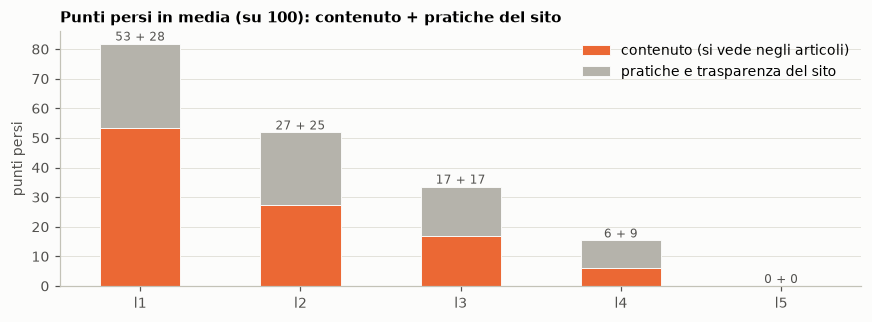

quota dei punti persi che riguarda il sito: {'l1': 0.35, 'l2': 0.47, 'l3': 0.5, 'l4': 0.6, 'l5': 0.0}


In [6]:
# 1.2 punti persi in media, per livello: quanti per il contenuto e quanti per il sito
persi = pd.DataFrame({k: sum(no[nome] * punti for nome, punti, tipo in criteri.values() if tipo == k) for k in ["contenuto", "sito"]})
media = persi.groupby(t.livello).mean()
media.plot.bar(stacked=True, color=[ARANCIO, CHIARO], rot=0, figsize=(8, 3))
for i, (c, s) in enumerate(media.to_numpy()):
    plt.text(i, c + s + 1, f"{c:.0f} + {s:.0f}", ha="center", fontsize=8, color=GRIGIO)
plt.title("Punti persi in media (su 100): contenuto + pratiche del sito"); plt.xlabel(""); plt.ylabel("punti persi")
plt.legend(["contenuto (si vede negli articoli)", "pratiche e trasparenza del sito"], loc="upper right")
mostra("1_punti_persi")
print("quota dei punti persi che riguarda il sito:", (media.sito / media.sum(axis=1)).fillna(0).round(2).to_dict())

## 2. Differenze semplici di stile

Per ogni articolo misuriamo alcune cose semplici (lunghezza, frasi, maiuscole, punti esclamativi, citazioni,
numeri, pronomi), poi prendiamo la **media di ogni testata**: così ogni testata conta una volta sola.

In [7]:
# 2.1 misure di stile per articolo, poi la media per testata
testo = art.text
parole = testo.str.split().str.len()
stile = pd.DataFrame({
    "parole per articolo": parole,
    "parole per frase": parole / testo.str.count(r"[.!?]+(?:\s|$)").clip(lower=1),
    "lettere per parola": testo.str.count(r"[A-Za-z]") / parole,
    "parole in maiuscolo (%)": testo.str.count(r"\b[A-Z]{3,}\b") / parole * 100,      # sigle comprese
    "punti esclamativi (‰)": testo.str.count("!") / parole * 1000,
    "punti di domanda (‰)": testo.str.count(r"\?") / parole * 1000,
    "virgolette (‰)": testo.str.count(r'["“”]') / parole * 1000,
    "numeri (‰)": testo.str.count(r"\b\d+") / parole * 1000,
    "io / noi (‰)": testo.str.count(r"\b(?:I|me|my|we|We|us|our|Our)\b") / parole * 1000,
    "tu / voi (‰)": testo.str.count(r"\b(?:you|You|your|Your)\b") / parole * 1000,
})
per_testata = stile.groupby(art.domain).mean().reindex(t.index)
per_testata.groupby(t.livello).median().round(2).T

livello,l1,l2,l3,l4,l5
parole per articolo,657.40,736.13,658.88,783.32,1148.67
parole per frase,21.41,23.44,22.46,23.21,23.28
lettere per parola,5.04,4.99,5.03,4.95,5.01
parole in maiuscolo (%),0.83,0.62,0.77,0.62,0.65
punti esclamativi (‰),0.59,0.21,0.39,0.29,0.20
punti di domanda (‰),1.38,0.75,1.01,1.52,1.39
virgolette (‰),16.60,18.20,18.28,17.87,17.58
numeri (‰),16.69,21.25,17.74,13.74,16.46
io / noi (‰),8.63,7.81,9.27,11.02,9.58
tu / voi (‰),3.41,2.47,2.61,3.30,3.00


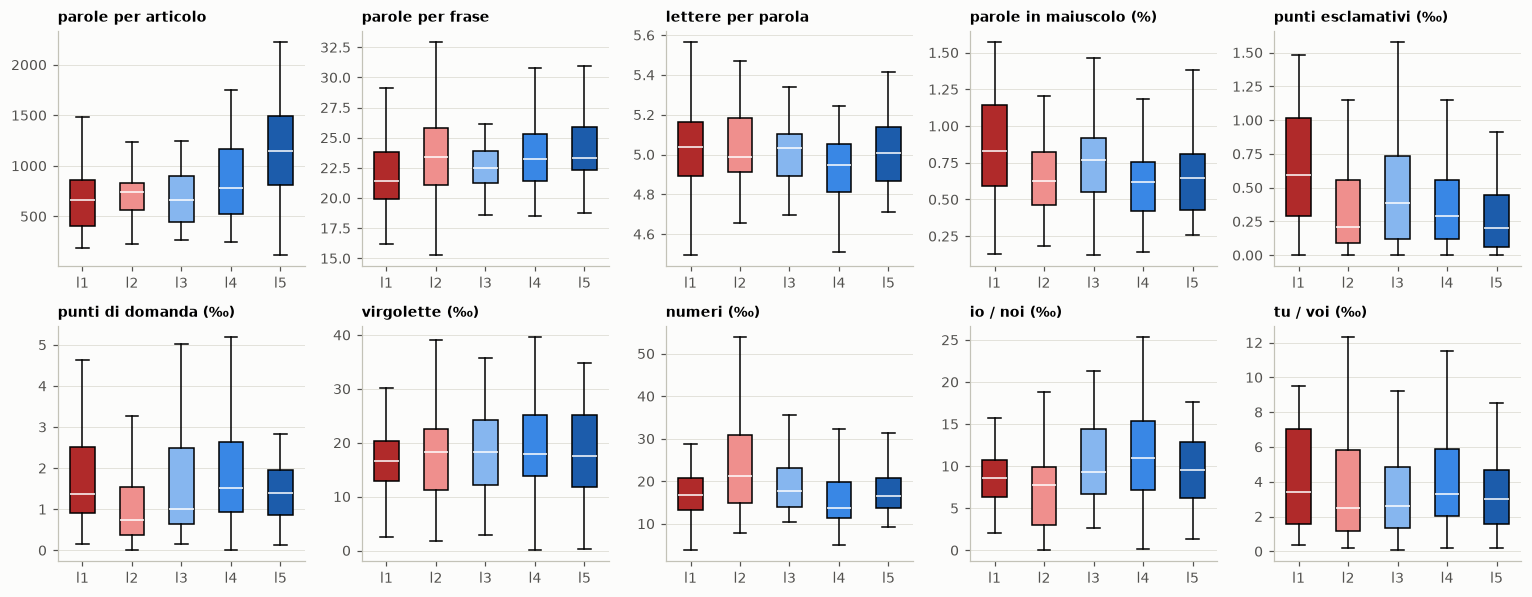

,H,p,differenza tra i livelli
misura,,,
parole per articolo,34.1,7.1e-07,sì
parole per frase,14.9,5.0e-03,sì
lettere per parola,13.8,7.9e-03,sì
parole in maiuscolo (%),18.5,9.7e-04,sì
punti esclamativi (‰),22.4,1.6e-04,sì
punti di domanda (‰),22.4,1.7e-04,sì
virgolette (‰),2.0,7.4e-01,no
numeri (‰),36.7,2.1e-07,sì
io / noi (‰),27.5,1.6e-05,sì


In [8]:
# 2.2 le stesse misure come distribuzioni (una scatola per livello) e quanto sono diverse tra i livelli (test di Kruskal-Wallis)
fig, assi = plt.subplots(2, 5, figsize=(14, 5.5))
risultati = []
for a, col in zip(assi.flat, per_testata.columns):
    gruppi = [per_testata[col][t.livello == l].dropna() for l in F.LIVELLI]
    box = a.boxplot(gruppi, tick_labels=F.LIVELLI, showfliers=False, patch_artist=True, medianprops={"color": "white"})
    for b, c in zip(box["boxes"], COLORE_LIVELLO):
        b.set_facecolor(c)
    H, p = kruskal(*gruppi)
    risultati.append({"misura": col, "H": round(H, 1), "p": p, "differenza tra i livelli": "sì" if p < 0.01 else "no"})
    a.set_title(col, fontsize=9)
mostra("2_stile")
pd.DataFrame(risultati).set_index("misura").assign(p=lambda d: d.p.map("{:.1e}".format))

## 3. Le parole tipiche di ogni livello

Per ogni livello cerchiamo le parole usate **più che negli altri livelli** (log-odds con prior informativo, Monroe et
al. 2008). Per non far pesare le testate con tanti articoli prendiamo al più 30 articoli per testata, e teniamo solo
parole usate da almeno 10 testate (così non escono i nomi propri di un solo sito).

In [9]:
# 3.1 conteggi delle parole su un campione bilanciato: al più 30 articoli per testata
campione = art.sample(frac=1, random_state=0).groupby("domain").head(30)
cv = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]{2,}\b", min_df=20)
C = cv.fit_transform(campione.text)
vocab = np.array(cv.get_feature_names_out())
di_testata = csr_matrix((np.ones(len(campione)), (pd.factorize(campione.domain)[0], np.arange(len(campione)))))   # testate × articoli
testate_per_parola = np.asarray(((di_testata @ (C > 0).astype(np.int32)) > 0).sum(0)).ravel()
tenute = testate_per_parola >= 10
print(f"{len(campione):,} articoli nel campione; {tenute.sum():,} parole usate da almeno 10 testate")

def log_odds(dentro, fuori, prior):
    """z-score del log-odds con prior di Dirichlet informativo (Monroe et al. 2008): > 0 = più usata 'dentro'."""
    a0, n1, n2 = prior.sum(), dentro.sum(), fuori.sum()
    d = np.log((dentro + prior) / (n1 + a0 - dentro - prior)) - np.log((fuori + prior) / (n2 + a0 - fuori - prior))
    return d / np.sqrt(1 / (dentro + prior) + 1 / (fuori + prior))

livelli_campione = pd.Categorical(campione.livello, categories=F.LIVELLI)
di_livello = csr_matrix((np.ones(len(campione)), (livelli_campione.codes, np.arange(len(campione)))), shape=(5, len(campione)))
conteggi = pd.DataFrame((di_livello @ C[:, tenute]).toarray(), index=F.LIVELLI, columns=vocab[tenute])     # livelli × parole
prior = conteggi.sum().to_numpy() * 0.01
tipiche = {}
for l in F.LIVELLI:
    z = log_odds(conteggi.loc[l].to_numpy(), conteggi.drop(l).sum().to_numpy(), prior)
    tipiche[l] = conteggi.columns[np.argsort(-z)[:15]]
pd.DataFrame(tipiche)

8,964 articoli nel campione; 13,986 parole usate da almeno 10 testate


,l1,l2,l3,l4,l5
0,gonna,com,labour,reform,china
1,iran,web,minnesota,israeli,rights
2,yeah,families,alpha,burnham,detention
3,president,park,gun,scotland,oklahoma
4,nato,pattern,firearms,palestinian,utah
5,cia,florida,firearm,farage,arab
6,japan,org,primaries,bush,human
7,russia,food,sussex,book,percent
8,omar,iowa,democrat,skin,asylum
9,okay,public,atf,settlers,states


In [10]:
# 3.2 affidabili (l3–l5) contro inaffidabili (l1–l2)
aff = conteggi.loc[["l3", "l4", "l5"]].sum().to_numpy(); inaff = conteggi.loc[["l1", "l2"]].sum().to_numpy()
z = pd.Series(log_odds(aff, inaff, prior), index=conteggi.columns).sort_values()
pd.DataFrame({"tipiche degli inaffidabili": z.index[:25], "tipiche degli affidabili": z.index[::-1][:25]})

,tipiche degli inaffidabili,tipiche degli affidabili
0,com,labour
1,florida,reform
2,web,cent
3,families,canada
4,org,burnham
5,gonna,detention
6,pattern,party
7,prosecutors,percent
8,park,rights
9,iowa,men


## 4. Una mappa delle testate

Ogni testata diventa la media dei vettori TF-IDF dei suoi articoli (che parole usa e quanto); poi riduciamo a 2
dimensioni (SVD + t-SNE) senza guardare le etichette. Se i livelli fossero ben separati, i colori formerebbero isole.

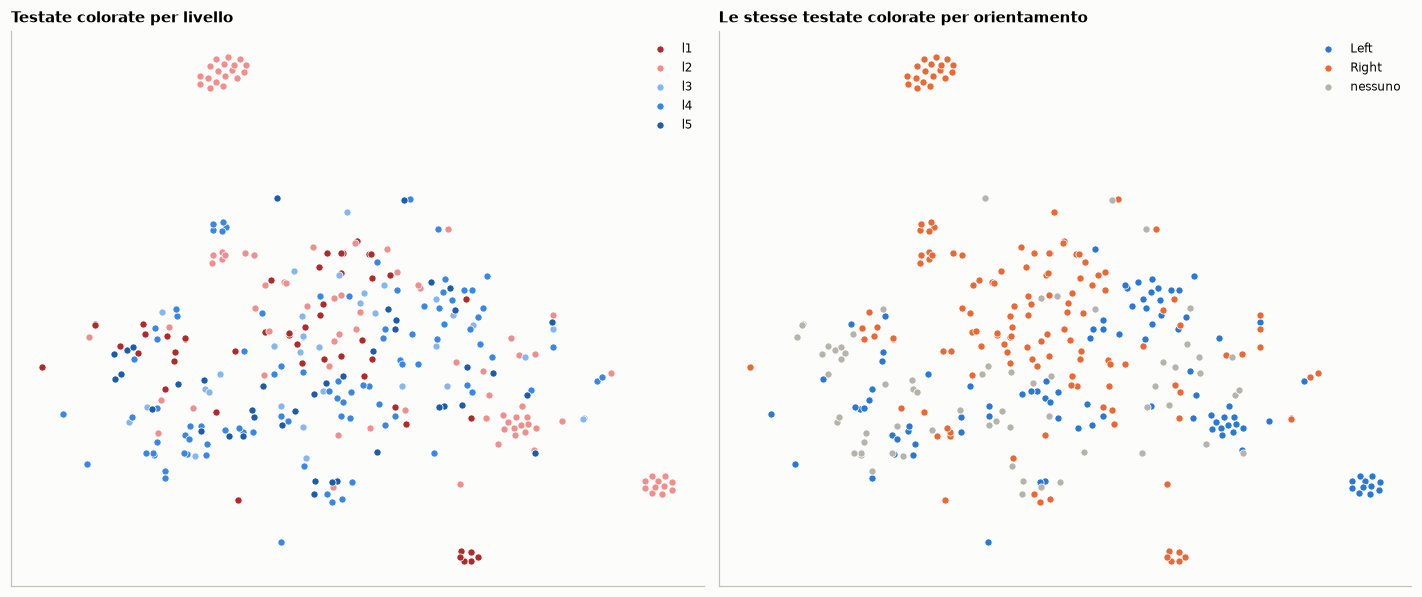

In [11]:
# 4.1 vettore medio di ogni testata e mappa 2D
vettori = F._tfidf()
X = vettori.fit_transform(art.text)                                  # senza etichette: serve solo per la mappa
indice = pd.Index(t.index)
M = csr_matrix((np.ones(len(art)), (indice.get_indexer(art.domain), np.arange(len(art)))), shape=(len(t), len(art)))
Xt = normalize(M @ X)                                                # una riga per testata
mappa = TSNE(2, perplexity=25, random_state=0, init="pca").fit_transform(TruncatedSVD(50, random_state=0).fit_transform(Xt))

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for k, l in enumerate(F.LIVELLI):
    m = (t.label == k).to_numpy()
    ax[0].scatter(mappa[m, 0], mappa[m, 1], s=22, color=COLORE_LIVELLO[k], label=l, edgecolor="white", linewidth=0.5)
for o, c in [("Left", BLU), ("Right", ARANCIO), ("nessuno", CHIARO)]:
    m = (t.orientamento == o).to_numpy()
    ax[1].scatter(mappa[m, 0], mappa[m, 1], s=22, color=c, label=o, edgecolor="white", linewidth=0.5)
ax[0].set_title("Testate colorate per livello"); ax[1].set_title("Le stesse testate colorate per orientamento")
for a in ax:
    a.set_xticks([]); a.set_yticks([]); a.legend(fontsize=8)
mostra("4_mappa")

## 5. Una scala di classificatori

Stessi 5 fold del tentativo 14 (un gruppo in un solo fold). Si parte dal più banale e si sale:

| classificatore | che cosa usa |
|---|---|
| **maggioranza** | predice sempre il livello più frequente nel training |
| **solo orientamento** | Left / Right / nessuno, nient'altro (non guarda il testo) |
| **stile** | le 10 misure della sezione 2 |
| **parole, per testata** | il vettore TF-IDF medio della testata (sezione 4) + regressione logistica |
| **parole, per articolo** | il classificatore a feature del tentativo 14 (ogni articolo, poi voto) |
| **ModernBERT troncato** e **a pezzi** | dal tentativo 14 (addestrati sugli articoli) |

In [12]:
# 5.1 i classificatori semplici, fold per fold (si addestra sulle testate degli altri fold)
def per_fold(feature, C=1.0):
    """Regressione logistica (classi bilanciate) addestrata sulle testate degli altri fold; ritorna il livello previsto."""
    prev = pd.Series(0, index=t.index)
    for k in range(1, 6):
        tr, te = (t.fold != k).to_numpy(), (t.fold == k).to_numpy()
        clf = LogisticRegression(C=C, max_iter=3000, class_weight="balanced").fit(feature[tr], t.label[tr])
        prev[te] = clf.predict(feature[te])
    return prev

maggioranza = pd.Series({d: t.label[t.fold != f].mode()[0] for d, f in t.fold.items()})
orientamento = pd.get_dummies(t.orientamento).to_numpy(float)
stile_z = StandardScaler().fit_transform(per_testata.fillna(per_testata.median()))

# parole per testata: il TF-IDF si costruisce a ogni fold sui soli articoli di training
def tfidf_del_fold(k):
    """Vettore TF-IDF medio di ogni testata, con il vocabolario e i pesi imparati sugli articoli degli altri fold."""
    v = F._tfidf().fit(art.text[art.fold != k])
    return k, normalize(M @ v.transform(art.text))

Xf = dict(Parallel(n_jobs=N_JOBS)(delayed(tfidf_del_fold)(k) for k in range(1, 6)))     # le teniamo anche per le sezioni 6 e 7
parole_testata = pd.Series(0, index=t.index)
for k, Xk in Xf.items():
    tr, te = (t.fold != k).to_numpy(), (t.fold == k).to_numpy()
    parole_testata[te] = LogisticRegression(C=10, max_iter=3000, class_weight="balanced").fit(Xk[tr], t.label[tr]).predict(Xk[te])
print("fatto")

fatto


In [13]:
# 5.2 i modelli del tentativo 14: previsioni salvate per ogni articolo (o pezzo), messe insieme per testata
cache = T14 / "Results/cache"
pf = pd.read_csv(cache / "feature_articoli.csv")
pt = pd.concat([pd.read_csv(f) for f in sorted((cache / "modernbert_troncato").glob("fold*.csv"))])
pp = pd.concat([pd.read_csv(f) for f in sorted((cache / "modernbert_pezzi").glob("fold*.csv"))])
voto = lambda df: df.assign(v=df[F.CLASSI].to_numpy().argmax(1)).groupby("domain").v.agg(F.voto)
media_prob = lambda df: pd.Series(df.groupby("domain")[F.CLASSI].mean().to_numpy().argmax(1), index=sorted(df.domain.unique()))

prev = {"maggioranza": maggioranza, "solo orientamento": per_fold(orientamento), "stile": per_fold(stile_z),
        "parole, per testata": parole_testata, "parole, per articolo (tentativo 14)": voto(pf),
        "ModernBERT troncato (tentativo 14)": media_prob(pt),
        "ModernBERT a pezzi (tentativo 14)": F.aggrega(pp)["media (pezzi → articolo), media (→ testata)"]}
prev = {k: v.reindex(t.index).to_numpy() for k, v in prev.items()}
scala = F.confronto(t.label, t.gruppo, prev, riferimenti=["parole, per articolo (tentativo 14)"])
scala[["F1 macro", "F1 macro IC", "accuratezza", "tolerant ±1", "binario", "ΔF1 vs parole, per articolo (tentativo 14)"]].round(3)

,F1 macro,F1 macro IC,accuratezza,tolerant ±1,binario,"ΔF1 vs parole, per articolo (tentativo 14)"
modello,,,,,,
maggioranza,0.093,[0.076; 0.112],0.303,0.545,0.545,-0.310 [-0.372; -0.232]
solo orientamento,0.230,[0.185; 0.276],0.310,0.653,0.675,-0.173 [-0.239; -0.091]
stile,0.245,[0.194; 0.297],0.257,0.666,0.563,-0.158 [-0.236; -0.063]
"parole, per testata",0.382,[0.308; 0.445],0.415,0.706,0.632,-0.021 [-0.087; +0.049]
"parole, per articolo (tentativo 14)",0.403,[0.332; 0.464],0.489,0.768,0.703,NaN
ModernBERT troncato (tentativo 14),0.272,[0.216; 0.331],0.307,0.666,0.619,-0.131 [-0.202; -0.046]
ModernBERT a pezzi (tentativo 14),0.284,[0.231; 0.344],0.322,0.724,0.613,-0.118 [-0.187; -0.037]


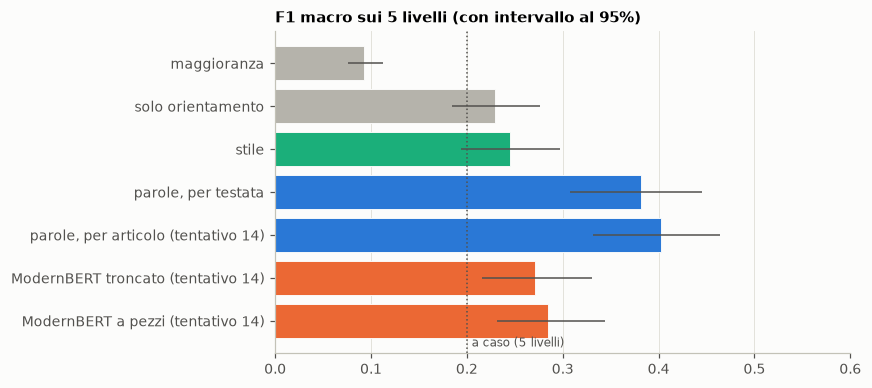

In [14]:
# 5.3 la scala in un grafico
ic = np.array([[float(x) for x in s.strip("[]").split(";")] for s in scala["F1 macro IC"]])
colori = [CHIARO, CHIARO, VERDE, BLU, BLU, ARANCIO, ARANCIO]
plt.figure(figsize=(8, 3.6))
plt.barh(scala.index[::-1], scala["F1 macro"][::-1], color=colori[::-1])
plt.errorbar(scala["F1 macro"][::-1], scala.index[::-1], xerr=[scala["F1 macro"][::-1] - ic[::-1, 0], ic[::-1, 1] - scala["F1 macro"][::-1]],
             fmt="none", ecolor=GRIGIO, lw=1)
plt.axvline(0.2, color=GRIGIO, ls=":", lw=1); plt.text(0.205, -0.6, "a caso (5 livelli)", fontsize=8, color=GRIGIO)
plt.title("F1 macro sui 5 livelli (con intervallo al 95%)"); plt.xlim(0, 0.6)
mostra("5_scala", "x")

## 6. Quali livelli si distinguono?

Per ogni coppia di livelli addestriamo un classificatore che distingue solo quei due (parole per testata, stessi fold)
e misuriamo l'**AUC**: 0,5 = non li distingue (come tirare una moneta), 1 = li separa perfettamente. Accanto, lo
stesso con il **solo orientamento**: quanto si distinguono senza guardare il testo.

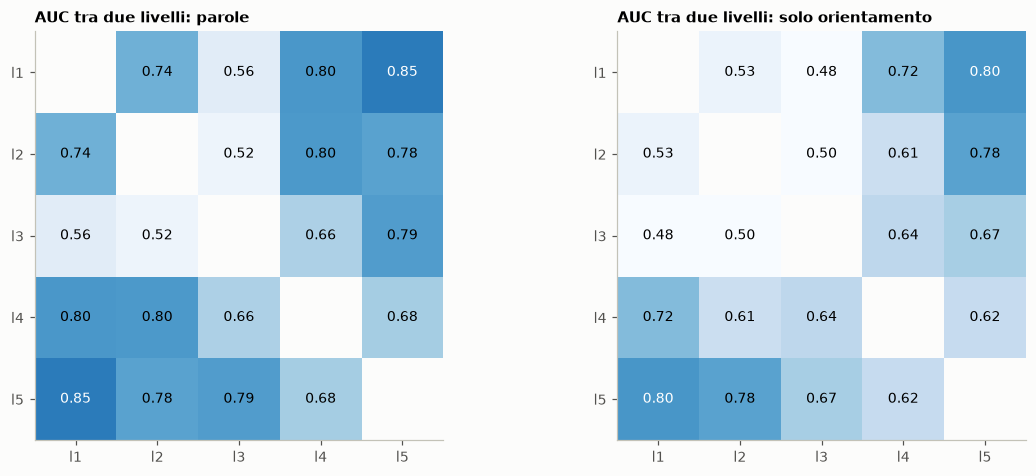

In [15]:
# 6.1 AUC per ogni coppia di livelli: con le parole e con il solo orientamento
def auc_coppia(a, b, feature_di):
    """AUC fuori fold di un classificatore che distingue il livello a dal livello b."""
    dentro = t.label.isin([a, b]).to_numpy()
    punteggi = pd.Series(np.nan, index=t.index)
    for k in range(1, 6):
        X = feature_di(k)
        tr, te = dentro & (t.fold != k).to_numpy(), dentro & (t.fold == k).to_numpy()
        if te.any():
            clf = LogisticRegression(C=10, max_iter=3000, class_weight="balanced").fit(X[tr], t.label[tr] == b)
            punteggi[te] = clf.predict_proba(X[te])[:, 1]
    return roc_auc_score(t.label[dentro] == b, punteggi[dentro])

auc = {nome: pd.DataFrame(np.nan, index=F.LIVELLI, columns=F.LIVELLI) for nome in ["parole", "solo orientamento"]}
for a in range(5):
    for b in range(a + 1, 5):
        auc["parole"].iloc[a, b] = auc["parole"].iloc[b, a] = auc_coppia(a, b, lambda k: Xf[k])
        auc["solo orientamento"].iloc[a, b] = auc["solo orientamento"].iloc[b, a] = auc_coppia(a, b, lambda k: orientamento)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for x, (nome, A) in zip(ax, auc.items()):
    x.imshow(A.to_numpy(float), cmap="Blues", vmin=0.5, vmax=1); x.grid(False)
    for i in range(5):
        for j in range(5):
            if i != j:
                x.text(j, i, f"{A.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if A.iloc[i, j] > 0.8 else "black")
    x.set_xticks(range(5), F.LIVELLI); x.set_yticks(range(5), F.LIVELLI); x.set_title(f"AUC tra due livelli: {nome}")
plt.tight_layout(); plt.savefig(GRAFICI / "6_coppie.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Dentro lo stesso orientamento

Se il testo servisse solo a riconoscere l'orientamento, dentro un orientamento non distinguerebbe più nulla. Proviamo:
solo testate di destra (o solo di sinistra), affidabili contro inaffidabili, sempre con le parole e gli stessi fold.

In [16]:
# 7.1 affidabili contro inaffidabili, separatamente per orientamento
righe = []
for o in ["Right", "Left", "nessuno"]:
    dentro = (t.orientamento == o).to_numpy()
    y = (t.label >= 2).to_numpy()
    punteggi = pd.Series(np.nan, index=t.index)
    for k in range(1, 6):
        tr, te = dentro & (t.fold != k).to_numpy(), dentro & (t.fold == k).to_numpy()
        if te.any() and len(set(y[tr])) == 2:
            clf = LogisticRegression(C=10, max_iter=3000, class_weight="balanced").fit(Xf[k][tr], y[tr])
            punteggi[te] = clf.predict_proba(Xf[k][te])[:, 1]
    ok = dentro & punteggi.notna().to_numpy()
    righe.append({"orientamento": o, "testate": int(dentro.sum()), "inaffidabili": int((dentro & ~y).sum()),
                  "affidabili": int((dentro & y).sum()), "AUC con le parole": round(roc_auc_score(y[ok], punteggi[ok]), 3)})
pd.DataFrame(righe).set_index("orientamento")

,testate,inaffidabili,affidabili,AUC con le parole
orientamento,,,,
Right,152,97,55,0.626
Left,104,38,66,0.726
nessuno,67,12,55,0.514


## 8. In breve

In [17]:
# 8.1 i numeri principali
f1 = scala["F1 macro"]
quota_sito = (media.sito / media.sum(axis=1)).dropna()               # le l5 non perdono punti
print(f"- punti NewsGuard persi per le pratiche del sito (non visibili negli articoli): dal {quota_sito.min():.0%} "
      f"al {quota_sito.max():.0%} dei punti persi, secondo il livello")
print(f"- misure di stile diverse tra i livelli (p < 0,01): {sum(r['p'] < 0.01 for r in risultati)} su {len(risultati)}")
print("- F1 macro: " + "; ".join(f"{k} {v:.3f}" for k, v in f1.items()))
coppie = auc["parole"].where(np.triu(np.ones((5, 5)), 1).astype(bool)).stack()
print(f"- coppie di livelli più facili: {coppie.idxmax()} (AUC {coppie.max():.2f}); più difficili: {coppie.idxmin()} (AUC {coppie.min():.2f})")

- punti NewsGuard persi per le pratiche del sito (non visibili negli articoli): dal 35% al 60% dei punti persi, secondo il livello
- misure di stile diverse tra i livelli (p < 0,01): 8 su 10
- F1 macro: maggioranza 0.093; solo orientamento 0.230; stile 0.245; parole, per testata 0.382; parole, per articolo (tentativo 14) 0.403; ModernBERT troncato (tentativo 14) 0.272; ModernBERT a pezzi (tentativo 14) 0.284
- coppie di livelli più facili: ('l1', 'l5') (AUC 0.85); più difficili: ('l2', 'l3') (AUC 0.52)


## 9. Che cosa ne concludiamo

- **L'etichetta guarda anche fuori dal testo.** Dal 35% (l1) al 60% (l4) dei punti persi viene da **pratiche del
  sito**: correzioni, proprietà, chi comanda, autori. Tra l2 e l3 cambiano soprattutto "raccoglie e presenta con cura"
  (89% contro 61% di no), le correzioni e la trasparenza, cose che un articolo mostra poco.
- **Lo stile cambia, ma poco.** 8 misure su 10 sono diverse tra i livelli:
  - le l5 scrivono articoli più lunghi;
  - le l1 usano più maiuscole e punti esclamativi;
  - le l2 usano più numeri.

  Da solo però lo stile arriva a F1 0,25, come il solo orientamento (0,23).
- **Le parole dicono soprattutto di che cosa e da dove si scrive**, non come:
  - politica britannica nelle l4;
  - diritti umani ed esteri nelle l5;
  - armi nelle l3;
  - linguaggio parlato nelle l1;
  - residui di siti aggregatori (com, web, org) nelle l2.
- **La mappa non mostra isole per livello**: le poche isole sono reti di siti costruiti con lo stesso modello, ognuna
  di un solo livello.
- **La scala di classificatori**:
  - maggioranza 0,09;
  - solo orientamento 0,23;
  - stile 0,25;
  - parole 0,38–0,40;
  - ModernBERT 0,27–0,28, sotto le parole.
- **Le coppie di livelli**:
  - gli estremi si separano (l1–l5 0,85; l1 e l2 contro l4 0,80), ma il solo orientamento fa già 0,80 su l1–l5;
  - i livelli vicini si confondono: l2–l3 0,52 (come a caso), l1–l3 0,56;
  - il confine affidabile/inaffidabile (60 punti) passa proprio tra l2 e l3.
- **Dentro lo stesso orientamento** il testo distingue ancora un po' affidabili e inaffidabili: sinistra 0,73,
  destra 0,63, testate senza orientamento 0,51.

**In una frase**: nei testi c'è un segnale reale ma debole, e in buona parte indiretto (orientamento, argomenti,
geografia, reti di siti). La differenza decisiva, tra l2 e l3, dipende soprattutto da pratiche del sito che negli
articoli non si vedono. Per questo nessun modello, semplice o complesso, va molto oltre F1 0,40.